# 01. Eksplorasi dataset lowongan (Fase 1)

**Tujuan:** memahami dataset sebelum membangun apa pun di atasnya: bentuknya, nilai yang kosong, sebaran, dan masalah
kualitas yang akan memengaruhi pencarian.

**Yang dipelajari:** EDA untuk data teks semi-terstruktur, memeriksa nilai kosong dan duplikat, menghitung frekuensi skill,
dan melihat sifat teks (panjang, bahasa) yang menentukan keputusan praproses.

Dataset ini sintetis. Pada data nyata, langkah yang sama dilakukan, tetapi temuannya biasanya jauh lebih berantakan.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nlp_engine import *
from nlp_engine.preprocessing import normalize_text, tokenize
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)
jobs, queries, qrels, ex = load_data("..")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
BLUE = "#2447F5"
print(jobs.shape)

(368, 16)


## 1. Bentuk dan tipe data

In [2]:
jobs.dtypes.to_frame("tipe").join(jobs.isna().sum().rename("kosong")).join(jobs.nunique().rename("nilai unik"))

,tipe,kosong,nilai unik
job_id,str,0,368
job_title,str,0,151
company,str,0,44
description,str,0,364
required_skills,str,0,54
preferred_skills,str,115,109
experience_level,str,0,5
location,str,0,10
employment_type,str,0,4
salary_min,float64,67,53


In [3]:
jobs.sample(3, random_state=1)[["job_id", "job_title", "company", "experience_level", "location", "employment_type", "required_skills"]]

,job_id,job_title,company,experience_level,location,employment_type,required_skills
301,J0302,Android Developer,Energi Hijau Nusantara,Mid-level,Denpasar,Kontrak,Android;Git
122,J0123,NLP Engineer,Awan Biru Cloud,Junior,Jakarta,Full-time,Python;Machine Learning;NLP
228,J0229,Junior Reporting Analyst,Aplikasi Rakyat,Entry Level,Jakarta,Full-time,Microsoft Excel;SQL


## 2. Nilai kosong
Kolom gaji dan skill nilai tambah memang sering kosong di lowongan nyata. Yang penting: tahu **seberapa banyak**, lalu putuskan
cara menanganinya (jangan mengisi gaji dengan rata-rata, misalnya, karena itu menciptakan data yang tidak ada).

In [4]:
miss = jobs[["salary_min", "salary_max", "preferred_skills", "required_skills", "description"]].copy()
miss["preferred_skills"] = miss["preferred_skills"].replace("", np.nan)
(miss.isna().mean() * 100).round(1).rename("% kosong").to_frame()

,% kosong
salary_min,18.2
salary_max,18.2
preferred_skills,31.2
required_skills,0.0
description,0.0


## 3. Sebaran kategori

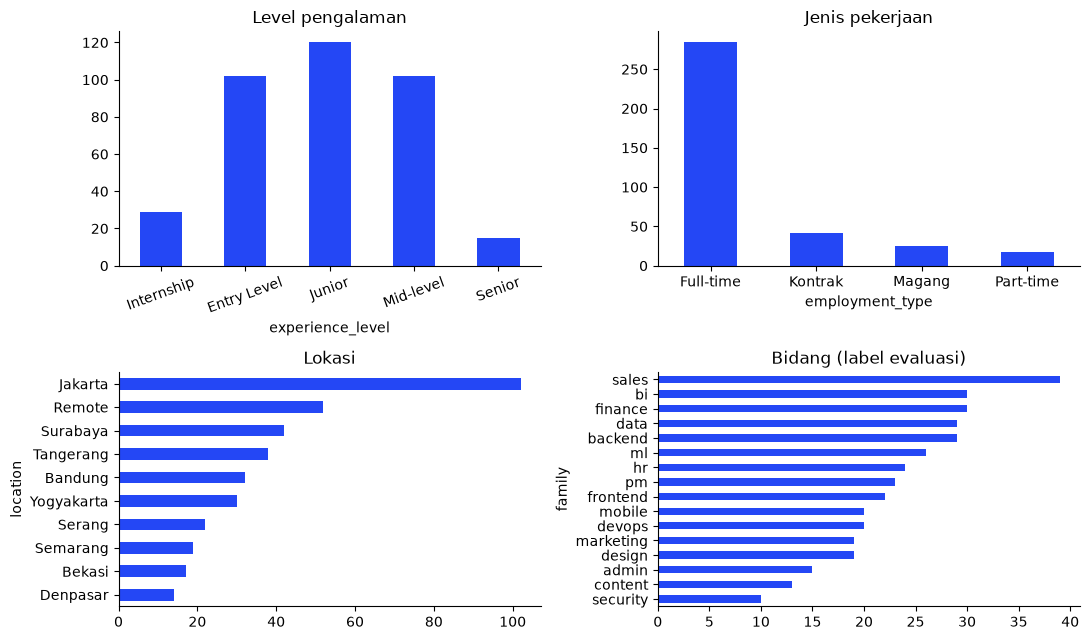

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
order = ["Internship", "Entry Level", "Junior", "Mid-level", "Senior"]
jobs.experience_level.value_counts().reindex(order).plot.bar(ax=axes[0, 0], color=BLUE, rot=20); axes[0, 0].set_title("Level pengalaman")
jobs.employment_type.value_counts().plot.bar(ax=axes[0, 1], color=BLUE, rot=0); axes[0, 1].set_title("Jenis pekerjaan")
jobs.location.value_counts().plot.barh(ax=axes[1, 0], color=BLUE).invert_yaxis(); axes[1, 0].set_title("Lokasi")
jobs.family.value_counts().plot.barh(ax=axes[1, 1], color=BLUE).invert_yaxis(); axes[1, 1].set_title("Bidang (label evaluasi)")
plt.tight_layout(); plt.show()

Perhatikan sebaran yang timpang: lowongan **Senior** sedikit, **Magang** sedikit, dan bidang seperti *frontend* lebih sedikit daripada *sales*.
Pencarian yang menyaring ketat berdasarkan level akan cepat kehabisan hasil untuk kategori kecil.

## 4. Gaji

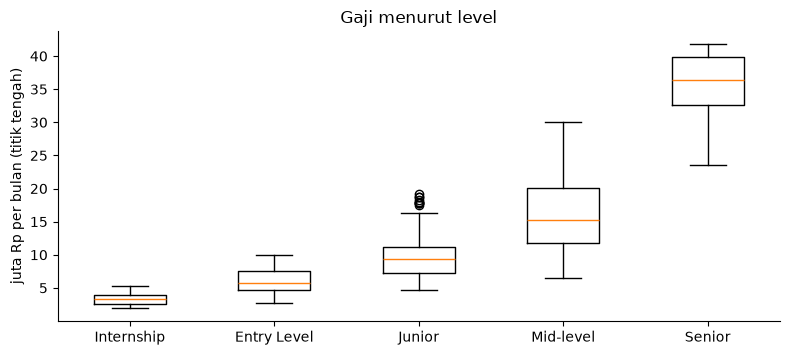

,count,median
experience_level,,
Internship,22,3.4
Entry Level,81,5.8
Junior,100,9.4
Mid-level,84,15.2
Senior,14,36.4


In [6]:
sal = jobs.dropna(subset=["salary_min", "salary_max"]).copy()
sal["mid"] = (sal.salary_min + sal.salary_max) / 2
fig, ax = plt.subplots(figsize=(8, 3.8))
data = [sal[sal.experience_level == l].mid for l in order]
ax.boxplot(data, showfliers=True); ax.set_xticklabels(order)
ax.set_ylabel("juta Rp per bulan (titik tengah)"); ax.set_title("Gaji menurut level"); plt.suptitle("")
plt.tight_layout(); plt.show()
sal.groupby("experience_level").mid.agg(["count", "median"]).reindex(order).round(1)

## 5. Teks deskripsi

        count   mean   std    min    25%    50%    75%    max
n_char  368.0  391.6  85.4  136.0  332.8  402.0  452.2  592.0
n_tok   368.0   46.2   9.6   19.0   40.0   47.0   52.2   68.0


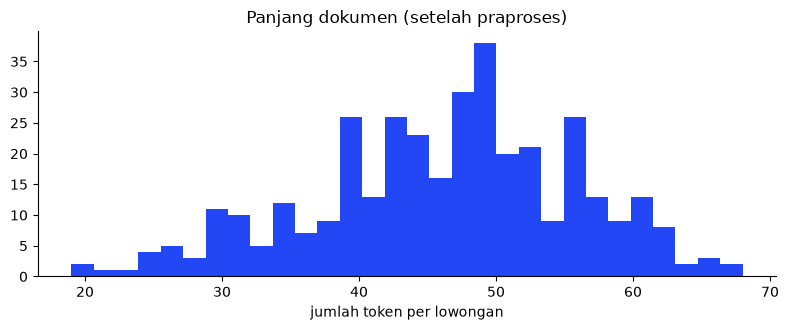

In [7]:
jobs["n_char"] = jobs.description.str.len()
jobs["n_tok"] = [len(preprocess(t, ex)) for t in job_text(jobs)]
print(jobs[["n_char", "n_tok"]].describe().round(1).T)
fig, ax = plt.subplots(figsize=(8, 3.4)); jobs.n_tok.hist(bins=30, ax=ax, color=BLUE, grid=False)
ax.set_xlabel("jumlah token per lowongan"); ax.set_title("Panjang dokumen (setelah praproses)"); plt.tight_layout(); plt.show()

Panjang dokumen cukup seragam, jadi parameter `b` pada BM25 (normalisasi panjang) tidak akan banyak berpengaruh di dataset ini.
Pada dataset nyata yang panjang deskripsinya sangat bervariasi, pengaruh `b` jauh lebih besar.

In [8]:
# perkiraan bahasa: berapa deskripsi yang tampaknya berbahasa Inggris?
EN = {"the", "and", "with", "will", "you", "we", "are", "for", "experience", "team"}
is_en = jobs.description.apply(lambda t: len(EN & set(normalize_text(t).split())) >= 3)
print(f"Berbahasa Inggris: {is_en.mean()*100:.1f}%   Berbahasa Indonesia: {(1-is_en.mean())*100:.1f}%")

Berbahasa Inggris: 28.0%   Berbahasa Indonesia: 72.0%


## 6. Skill
Skill di sini sudah berupa label terstruktur. Lihat skill apa yang paling dibutuhkan dan seberapa sering sepasang skill muncul bersama.
Pasangan yang sering bersama adalah sinyal bahwa dua skill saling berkaitan (dasar untuk pencarian skill terkait).

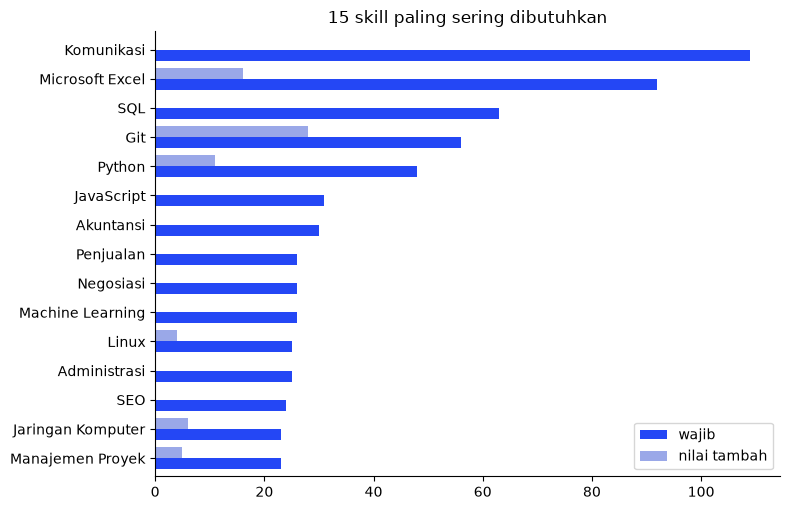

In [9]:
split = lambda v: [s for s in str(v).split(";") if s and s != "nan"]
req = Counter(s for v in jobs.required_skills for s in split(v))
pref = Counter(s for v in jobs.preferred_skills for s in split(v))
top = pd.DataFrame({"wajib": pd.Series(req), "nilai tambah": pd.Series(pref)}).fillna(0).astype(int)
top = top.sort_values("wajib", ascending=False)
top.head(15).iloc[::-1].plot.barh(figsize=(8, 5.2), color=[BLUE, "#9AA8E8"], width=.75)
plt.title("15 skill paling sering dibutuhkan"); plt.tight_layout(); plt.show()

In [10]:
# skill yang sering muncul bersama (jumlah lowongan yang memuat keduanya)
from itertools import combinations
pair = Counter()
for v, p in zip(jobs.required_skills, jobs.preferred_skills):
    s = sorted(set(split(v)) | set(split(p)))
    pair.update(combinations(s, 2))
pd.DataFrame([{"skill A": a, "skill B": b, "lowongan": n} for (a, b), n in pair.most_common(10)])

,skill A,skill B,lowongan
0,Microsoft Excel,SQL,44
1,Komunikasi,Microsoft Office,38
2,Komunikasi,Microsoft Excel,34
3,Git,REST API,32
4,Akuntansi,Microsoft Excel,30
5,Microsoft Excel,Power BI,27
6,Power BI,SQL,27
7,Docker,Python,27
8,Komunikasi,Negosiasi,26
9,Komunikasi,Penjualan,26


In [11]:
# skill di kamus yang tidak pernah dibutuhkan satu lowongan pun (kandidat dibuang atau data kurang)
used = set(req) | set(pref)
print("Tidak dipakai:", sorted(set(ex.names) - used) or "tidak ada")

Tidak dipakai: tidak ada


## 7. Duplikat
Portal lowongan nyata penuh posting ulang. Kolom `dup_of` menandai 8 posting ulang yang sengaja dibuat. Sebelum membuat detektor,
lihat dulu seberapa miripnya isi mereka dengan aslinya.

In [12]:
dups = jobs[jobs.dup_of.notna() & (jobs.dup_of != "")]
orig = jobs.set_index("job_id")
tok = lambda s: set(normalize_text(s).split())
rows = []
for r in dups.itertuples():
    o = orig.loc[r.dup_of]
    a, b = tok(r.description), tok(o.description)
    rows.append({"posting ulang": r.job_id, "asli": r.dup_of, "judul": r.job_title, "jaccard deskripsi": round(len(a & b) / len(a | b), 2)})
pd.DataFrame(rows)

,posting ulang,asli,judul,jaccard deskripsi
0,J0361,J0340,Content Writer (Fresh Graduate),1.00
1,J0362,J0305,Flutter Developer Internship,1.00
2,J0363,J0302,Android Developer,0.92
3,J0364,J0299,Mid-level Node.js Developer,0.91
4,J0365,J0184,Customer Service Officer (Fresh Graduate),1.00
5,J0366,J0260,Business Intelligence Analyst,0.89
6,J0367,J0178,Reporting Analyst (Fresh Graduate),0.91
7,J0368,J0169,Data Scientist,0.85


In [13]:
# bandingkan dengan pasangan lowongan BERBEDA yang judul dan perusahaannya sama: apakah itu juga duplikat?
same = jobs[~jobs.job_id.isin(dups.job_id)].groupby(["job_title", "company"]).job_id.apply(list)
same = same[same.apply(len) > 1]
print(f"{len(same)} pasangan judul+perusahaan kembar di luar posting ulang yang disengaja. Contoh:")
same.head(5)

10 pasangan judul+perusahaan kembar di luar posting ulang yang disengaja. Contoh:


job_title           company              
Admin Data Entry    Kopi Lintas Digital      [J0045, J0328]
                    Studio Kreasi Lokal      [J0135, J0199]
Analis Riset Pasar  Properti Cakrawala       [J0174, J0320]
Data Engineer       Aplikasi Rakyat          [J0018, J0356]
Frontend Developer  Teknologi Kota Pintar    [J0163, J0354]
Name: job_id, dtype: object

Kalau ada lowongan dengan judul dan perusahaan yang sama tetapi isi berbeda, kemungkinan itu memang dua lowongan lain
(misalnya beda kota). Aturan duplikat yang hanya melihat judul dan perusahaan akan salah menghapusnya.

## Temuan yang perlu dibawa ke fase berikutnya
1. Deskripsi bercampur bahasa Indonesia dan Inggris, jadi praproses dan embedding harus menangani keduanya.
2. Kategori kecil (Magang, Senior) membuat filter ketat berisiko menghasilkan daftar kosong.
3. Gaji kosong pada sekitar seperlima lowongan, jadi filter gaji harus memutuskan perilaku untuk lowongan tanpa gaji.
4. Ada duplikat yang mirip tetapi tidak identik, jadi deteksi perlu kemiripan teks, bukan kecocokan persis.

> **Latihan 13.** Buat pemeriksaan kualitas data otomatis (fungsi yang mengembalikan daftar peringatan) lalu jalankan pada
> `jobs.csv` setiap kali admin mengimpor CSV baru.

> **Latihan 14.** Tambahkan 20 baris lowongan yang sengaja rusak (tanpa judul, lokasi tidak dikenal, gaji min > maks) dan lihat
> bagian mana dari pipeline yang gagal diam-diam.